# 03 · Metric and baselines

Writes the competition metric, fixes how a validation score is computed and sets the scores to beat without an image model. No test score here: this is a code competition, so submissions come in 06. Each section ends with key findings.

**Contents**
1. Writing the competition metric
2. What to predict for the slices of other stacks
3. Baselines from the label rates and the slice position
4. LightGBM on metadata and pixel statistics
5. Reference points that use the labels
6. How precise is the validation?

Needs `slices.csv` and `series.csv` from `scripts/prepare_data.py` (02). No image is read.

In [1]:
import subprocess
import sys
import time

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pe.data.prepare import IMAGE_LABEL, N_FOLDS, SEED, SERIES_LABELS, read_series, read_slices
from pe.metrics import EPS, IMAGE_WEIGHT, SERIES_WEIGHTS, bootstrap, image_weights, log_losses, paired_bootstrap, score, score_by_label, series_losses
from pe.paths import REPO_ROOT, load_paths

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

PROCESSED = load_paths()["processed_data_dir"]
slices, series = read_slices(PROCESSED / "slices.csv"), read_series(PROCESSED / "series.csv")
train_series = series[series["split"] == "train"].reset_index(drop=True)
train = slices[slices["split"] == "train"].reset_index(drop=True)
test = slices[slices["split"] == "test"].reset_index(drop=True)

row_of = pd.Series(train_series.index, index=train_series["series"])
image_series = train["series"].map(row_of).to_numpy()
y_series = train_series[SERIES_LABELS].astype(float).to_numpy()
y_image = train[IMAGE_LABEL].astype(float).to_numpy()
main = train["main"].to_numpy()
series_fold = train_series["fold"].astype(int).to_numpy()
fold = series_fold[image_series]
weights = image_weights(image_series, y_image)
q = weights / IMAGE_WEIGHT
RARE_IN_TEST = ["dcm4che-1.4.35", "dcm4che-1.4.37"]  # 2 of the 650 test series (section 4)
test_like = ~train_series["writer"].isin(RARE_IN_TEST).to_numpy()
print(f"train: {len(train_series):,} series, {len(train):,} slices ({main.sum():,} in main stacks) | positive slices: {int(y_image.sum()):,} in {(np.bincount(image_series, weights=y_image) > 0).sum():,} series")

train: 7,279 series, 1,790,594 slices (1,756,666 in main stacks) | positive slices: 96,540 in 2,211 series


## 1. Writing the competition metric

Per series, the log loss of the nine series labels with their weights $w_j$, which add up to 1. Per slice, the log loss with the weight $w\,q_i$, where $w$ = 0.0736 and $q_i = m_i / n_i$ is the share of positive slices in the series:

$$\text{score}=\frac{\sum_i\sum_j w_j\,\text{BCE}_{ij} + \sum_i\sum_k w\,q_i\,\text{BCE}_{ik}}{N + w\sum_i m_i}$$

Kaggle never published its code, so `src/pe/metrics.py` follows this formula, with predictions clipped to [1e-15, 1 − 1e-15] (our assumption):
- `score`: the competition score;
- `series_losses`: loss and weight of every series, for the intervals of section 6;
- `score_by_label`: the loss of each label and its share of the score.

The unit tests in `tests/test_metrics.py` check it on cases whose answer is known:
- a perfect prediction scores 0, a constant 0.5 scores ln 2;
- the score equals scikit-learn's `log_loss` with the weights of the formula, and a small case worked out by hand;
- slices of a series without positive slices do not count;
- $q_i$ divides by all slices of the series, the denominator counts positive slices, not rows;
- predictions are clipped at 1e-15; the bootstrap resamples whole series.

In [2]:
tests = subprocess.run([sys.executable, "-m", "pytest", "tests/test_metrics.py", "-q", "--color=no", "-p", "no:cacheprovider", "-W", "ignore"],
                       cwd=REPO_ROOT, capture_output=True, text=True)
print(tests.stdout.strip().splitlines()[-1])
assert tests.returncode == 0, tests.stdout

15 passed in 4.83s


Where does the score come from? The weight of each label, over all train series:

In [3]:
shares = pd.Series(np.append(SERIES_WEIGHTS * len(y_series), IMAGE_WEIGHT * y_image.sum()) / (len(y_series) + IMAGE_WEIGHT * y_image.sum()),
                   index=SERIES_LABELS + [IMAGE_LABEL], name="% of the total weight") * 100
display(shares.sort_values(ascending=False).round(1).to_frame().T)
positive_q = pd.Series(q).groupby(image_series).first()
positive_q = positive_q[positive_q > 0]
print(f"q in the positive series: median {positive_q.median():.3f} | largest {positive_q.max():.3f}")

,pe_present_on_image,rv_lv_ratio_gte_1,central_pe,chronic_pe,acute_and_chronic_pe,indeterminate,rv_lv_ratio_lt_1,negative_exam_for_pe,rightsided_pe,leftsided_pe
% of the total weight,49.4,11.9,9.5,5.3,5.3,4.7,4.0,3.7,3.2,3.2


q in the positive series: median 0.144 | largest 0.870


How expensive is a confident mistake? The loss of one value for a few predictions, and what it adds to one series through the largest series label and through one slice at the median $q$:

In [4]:
p = np.array([0.5, 0.1, 0.01, 0.001, 1e-6, 1e-15])
pd.DataFrame({"predicted": [f"{v:g}" for v in p], "loss if the label is 1": -np.log(p), "loss if the label is 0": -np.log1p(-p),
              "missed rv_lv_ratio_gte_1": SERIES_WEIGHTS[SERIES_LABELS.index("rv_lv_ratio_gte_1")] * -np.log(p),
              "missed slice at the median q": IMAGE_WEIGHT * positive_q.median() * -np.log(p)}).round(4)

,predicted,loss if the label is 1,loss if the label is 0,missed rv_lv_ratio_gte_1,missed slice at the median q
0,0.5,0.6931,0.6931,0.1627,0.0074
1,0.1,2.3026,0.1054,0.5403,0.0244
2,0.01,4.6052,0.0101,1.0807,0.0489
3,0.001,6.9078,0.0010,1.6210,0.0733
4,1e-06,13.8155,0.0000,3.2420,0.1466
5,1e-15,34.5388,0.0000,8.1050,0.3665


A missed `rv_lv_ratio_gte_1` at 0.001 adds 1.62 to the loss of a series. At the target score of 0.148, an average series carries about 0.29 (the score × its weight of about 1.98), so this one mistake costs 5.5 times that. A missed slice costs far less, but a positive series has many of them.

### 1.1 Key findings

- **`pe.metrics.score` computes the competition score:** it passes its 15 unit tests.
- **The slices carry 49.4% of the total weight,** as much as the nine series labels together. `rv_lv_ratio_gte_1` (11.9%) and `central_pe` (9.5%) lead the series labels.
- **A confident miss is expensive:** at 0.001 a series label costs up to 1.62, one slice at the median q 0.073.

## 2. What to predict for the slices of other stacks

The models train on main stacks, and the slices of other stacks get a fixed low prediction (02, 3.1). They still count in the metric. Train cannot show the risk, since none of them is positive there. How many are there?

In [5]:
other_positive = ~main & (q > 0)
test_other = test[~test["main"]]
stacks_by_split = series.groupby("split")["n_stacks"].agg(series="size", with_several_stacks=lambda s: (s > 1).sum())
stacks_by_split["other-stack slices"] = [(~test["main"]).sum(), (~main).sum()]
stacks_by_split["% of the slices"] = (stacks_by_split["other-stack slices"] / [len(test), len(train)] * 100).round(2)
display(stacks_by_split)
print(f"train: other-stack slices in positive series: {other_positive.sum():,} in {len(set(image_series[other_positive]))} series | positive among them: {int(y_image[~main].sum())}")
print("test:", test_other[["series", "stack", "tilt", "n_slices"]].to_dict("records"))
series.assign(several=series["n_stacks"] > 1).groupby(["writer", "split"])["several"].agg(series="size", several_stacks="sum").unstack(fill_value=0)

,series,with_several_stacks,other-stack slices,% of the slices
split,,,,
test,650,1,1,0.00
train,7279,158,33928,1.89


train: other-stack slices in positive series: 12,179 in 43 series | positive among them: 0
test: [{'series': '0cfc61e46f28', 'stack': 0, 'tilt': 86.86009769340873, 'n_slices': 1}]


series       several_stacks      
split            test train           test train
writer                                          
(none)            416  3819              0     1
PYDICOM 1.2.2     190  1621              0     0
dcm4che-1.4.35      2   870              0    55
dcm4che-1.4.37      0   762              0   102
dcm4che-1.4.38     42   207              1     0

Other stacks are almost absent from the test files: one slice in 650 series, tilted by 87°. 157 of the 158 train series with several stacks come from two writers, which hold 2 of the 650 test series. The other 1,517 test series are hidden, so their count is unknown, but it should be small too.

What does a low value cost? Added to the score, for each value: on train, where every such slice is negative, and on a test set of 2,167 series if some of them were positive (at the median q of these series):

In [6]:
N_TEST = 2167  # 650 series we can read + 1,517 hidden ones (data paper)
denominator = len(y_series) + IMAGE_WEIGHT * y_image.sum()
denominator_test = N_TEST * denominator / len(y_series)  # assuming the positive slices per series of train
q_other = pd.Series(q[other_positive]).groupby(image_series[other_positive]).first().median()
per_slice = IMAGE_WEIGHT * q_other / denominator_test
rows = []
for p in [EPS, 1e-6, 1e-4, 1e-3, 1e-2]:
    rows.append({"predicted": f"{p:g}", "added on train (no positive there)": (weights[~main] * -np.log1p(-p)).sum() / denominator,
                 **{f"{k} positive in test": k * per_slice * -np.log(p) for k in [1, 10, 100, 1000]}})
print(f"median q of those {len(set(image_series[other_positive]))} series: {q_other:.3f}")
pd.DataFrame(rows).set_index("predicted").map(lambda v: f"{v:.6f}")

median q of those 43 series: 0.039


,added on train (no positive there),1 positive in test,10 positive in test,100 positive in test,1000 positive in test
predicted,,,,,
1e-15,0.000000,0.000023,0.000234,0.002344,0.023435
1e-06,0.000000,0.000009,0.000094,0.000937,0.009374
0.0001,0.000000,0.000006,0.000062,0.000625,0.006249
0.001,0.000003,0.000005,0.000047,0.000469,0.004687
0.01,0.000033,0.000003,0.000031,0.000312,0.003125


**Decision**
- **Slices of other stacks get 0.001 instead of an exact 0.** The models never see these slices, but the metric asks for a prediction, so we write a fixed value. The loss of one slice, before its weight:

  | The slice is | Predicted 0 | Predicted 0.001 |
  |---|---|---|
  | negative | 0 | 0.001 |
  | positive | 34.5 (infinite if Kaggle does not clip) | 6.9 |

  All these slices are negative in train, so 0.001 adds only 0.000003 to the score there. In exchange, an unexpected positive slice in the test set costs five times less and cannot make the score infinite.

### 2.1 Key findings

- **All 12,179 other-stack slices in positive train series are negative,** and the test files hold just one such slice.
- **Under these assumptions (q = 0.039, the positive slices per series of train) the risk is small either way:** with 10 positive slices in the hidden test series, an exact 0 costs 0.0002 and 0.001 costs 0.00005, both below the noise of section 6. Only hundreds of them would matter (100 slices: 0.0023 and 0.0005).

In [7]:
OTHER_STACK = 1e-3  # the prediction for every slice outside the main stack

## 3. Baselines from the label rates and the slice position

Every score is out of fold: the series of fold *k* get the rates of the other four folds, so each score covers all 7,279 series. The tables show two scores (section 4 explains why):
- the **test-like score**, on the 5,647 series of the three writers that make up 648 of the 650 test series we can read;
- the **full score**, on all 7,279 series, also split into its two parts.

The simplest prediction gives each series label its rate. For the slices there are two options, the plain rate and the rate weighted by q, since the metric weighs slices by q:

In [8]:
predictions = {}


def evaluate(names):
    rows = {}
    for name in names:
        loss, weight = series_losses(y_series, predictions[name][0], image_series, y_image, predictions[name][1])
        image = score_by_label(y_series, predictions[name][0], image_series, y_image, predictions[name][1])[IMAGE_LABEL]["share of the score"]
        rows[name] = {"test-like": loss[test_like].sum() / weight[test_like].sum(), "full": loss.sum() / weight.sum(), "full: series labels": loss.sum() / weight.sum() - image,
                      "full: slices": image, "the other two writers": loss[~test_like].sum() / weight[~test_like].sum()}
    return pd.DataFrame(rows).T.round(4)


def oof_series_rates():
    p = np.zeros_like(y_series)
    for f in range(N_FOLDS):
        p[series_fold == f] = y_series[series_fold != f].mean(axis=0)
    return p


def oof_image_rates(keys=None):
    # Out of fold: the main slices of each fold get the q-weighted positive rate of their group in the other folds; a group not seen, the overall rate.
    # A rate of exactly 0 or 1 is kept 1e-4 away from the ends.
    p = np.full(len(y_image), OTHER_STACK)
    for f in range(N_FOLDS):
        fit, val = main & (fold != f), main & (fold == f)
        overall = np.average(y_image[fit], weights=weights[fit])
        if keys is None:
            p[val] = overall
            continue
        table = train.loc[fit, keys].assign(loss=(weights * y_image)[fit], weight=weights[fit]).groupby(keys)[["loss", "weight"]].sum()
        rate = (table["loss"] / table["weight"]).rename("rate")
        p[val] = train.loc[val, keys].join(rate, on=keys)["rate"].fillna(overall).clip(1e-4, 1 - 1e-4).to_numpy()
    return p


series_rates = oof_series_rates()
plain = np.zeros_like(y_image)
for f in range(N_FOLDS):
    plain[fold == f] = y_image[fold != f].mean()
predictions["plain slice rate"] = (series_rates, plain)
predictions["q-weighted slice rate"] = (series_rates, oof_image_rates())
print(f"slice rate: plain {y_image.mean():.3f} | weighted by q {np.average(y_image, weights=weights):.3f}")
display(evaluate(["plain slice rate", "q-weighted slice rate"]))
pd.DataFrame(score_by_label(y_series, predictions["q-weighted slice rate"][0], image_series, y_image, predictions["q-weighted slice rate"][1])).sort_values("share of the score", axis=1, ascending=False).round(4)

slice rate: plain 0.054 | weighted by q 0.290


,test-like,full,full: series labels,full: slices,the other two writers
plain slice rate,0.5754,0.5988,0.1611,0.4377,0.6622
q-weighted slice rate,0.4427,0.4574,0.1611,0.2963,0.4973


,pe_present_on_image,rv_lv_ratio_gte_1,negative_exam_for_pe,central_pe,rv_lv_ratio_lt_1,rightsided_pe,leftsided_pe,chronic_pe,acute_and_chronic_pe,indeterminate
log loss,0.5998,0.3847,0.6308,0.2132,0.4631,0.5705,0.5167,0.1683,0.0977,0.1041
share of the score,0.2963,0.0457,0.0235,0.0203,0.0183,0.0181,0.0164,0.0089,0.0052,0.0048


Weighting by q takes the slice rate from 5.4% to 29.0% and the score down by 0.14. The slices make up two thirds of this score, and `rv_lv_ratio_gte_1` is the most expensive series label.

Positive slices lie in the middle of the main stack. The rate by the place in the stack, then the score with 8 and 20 steps of the relative place (other stacks: 0.001):

q-weighted rate: largest 74.0% | first step 0.2% | last step 0.2%


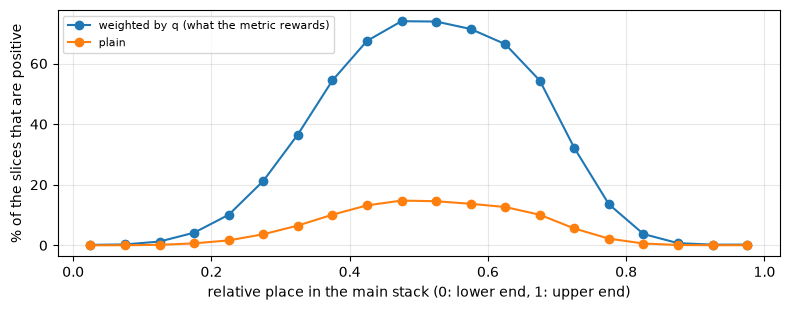

,test-like,full,full: series labels,full: slices,the other two writers
plain slice rate,0.5754,0.5988,0.1611,0.4377,0.6622
q-weighted slice rate,0.4427,0.4574,0.1611,0.2963,0.4973
"rate by place, 8 steps",0.3412,0.3494,0.1611,0.1883,0.3715
"rate by place, 20 steps",0.3354,0.3432,0.1611,0.1821,0.3642


In [9]:
train["rel"] = train["slice"] / (train["n_slices"] - 1).clip(lower=1)
train["rel_bin"] = (train["rel"] * 20).clip(upper=19.99).astype(int)
train["rel_bin_8"] = (train["rel"] * 8).clip(upper=7.99).astype(int)
stacks = train[main].assign(y=y_image[main], weight=weights[main], loss=(weights * y_image)[main])
curve = stacks.groupby("rel_bin")[["loss", "weight"]].sum()
plain_curve = stacks.groupby("rel_bin")["y"].mean()
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot((curve.index + 0.5) / 20, curve["loss"] / curve["weight"] * 100, marker="o", label="weighted by q (what the metric rewards)")
ax.plot((plain_curve.index + 0.5) / 20, plain_curve * 100, marker="o", label="plain")
print(f"q-weighted rate: largest {(curve['loss'] / curve['weight']).max():.1%} | first step {(curve['loss'] / curve['weight']).iloc[0]:.1%} | last step {(curve['loss'] / curve['weight']).iloc[-1]:.1%}")
ax.set_xlabel("relative place in the main stack (0: lower end, 1: upper end)")
ax.set_ylabel("% of the slices that are positive")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

predictions["rate by place, 8 steps"] = (series_rates, oof_image_rates(["rel_bin_8"]))
predictions["rate by place, 20 steps"] = (series_rates, oof_image_rates(["rel_bin"]))
evaluate(["plain slice rate", "q-weighted slice rate", "rate by place, 8 steps", "rate by place, 20 steps"])

On the test set, [OsciiArt's public notebook](https://www.kaggle.com/code/osciiart/baseline-with-no-image) scored 0.56 public with the plain rate, 0.44 public with the q-weighted rate, and 0.33 public and 0.336 private with 8 steps. Those predictions were fitted on all of train and gave every slice a rate, so the comparison is rough.

### 3.1 Key findings

- **Weighting by q is what the metric asks for:** the full score falls from 0.5988 to 0.4574.
- **The place in the stack takes off another 0.114:** a full score of 0.3432 with 20 steps, 0.0062 better than 8. The q-weighted rate reaches 74% in the middle of the stack, and about 0 at both ends.
- **The series labels stay at 0.1611:** constant rates know nothing about a series.

## 4. LightGBM on metadata and pixel statistics

Without an image model, the tables hold more about a slice than its place: the spacing, where the file came from, and the pixel statistics of 02, 7.3. Two kinds of models, all fitted on main stacks:
- **slices:** one model, trained on the positive series with the weight q, since the metric counts nothing else;
- **series labels:** one model per label, on one row per series.

| Group | Per slice | Per series |
|---|---|---|
| place | `slice`, `n_slices`, `rel`, mm from both ends | `n_slices`, `n_main`, `length_mm` |
| spacing | `thickness`, `pixel_spacing`, `local_spacing`, `gap_prev`, `gap_next`, `n_stacks`, `tilt` | `thickness`, `pixel_spacing`, `n_stacks`, `tilt` |
| site | `writer`, `group` | `writer`, `group` |
| pixels | `body_share`, `lung_share`, height and width of both boxes in mm, `lung_share` of the neighbours and relative to the stack's largest | body and lung volume (ml), mean and largest shares, largest box sizes in mm |

The writer stands for the site, so we look at it first, and at how it differs from test:

In [10]:
SITE = ["writer", "group"]
for col in SITE:
    train[col] = train["series"].map(train_series.set_index("series")[col])
stack_pos = train.groupby(["series", "stack"])["pos"]
train["mm_from_bottom"] = train["pos"] - stack_pos.transform("min")
train["mm_to_top"] = stack_pos.transform("max") - train["pos"]
for part in ["body", "lung"]:
    missing = train[f"{part}_top"] < 0
    train[f"{part}_height_mm"] = ((train[f"{part}_bottom"] - train[f"{part}_top"]) * train["pixel_spacing"]).mask(missing)
    train[f"{part}_width_mm"] = ((train[f"{part}_right"] - train[f"{part}_left"]) * train["pixel_spacing"]).mask(missing)
    train[f"{part}_area_cm2"] = train[f"{part}_share"] * 512 ** 2 * train["pixel_spacing"] ** 2 / 100
by_stack = train.groupby(["series", "stack"])["lung_share"]
train["lung_share_below"], train["lung_share_above"] = by_stack.shift(1), by_stack.shift(-1)
train["lung_share_relative"] = train["lung_share"] / by_stack.transform("max").replace(0, np.nan)


def categories(frame):
    frame = frame.copy()
    for col in set(SITE) & set(frame.columns):
        frame[col] = pd.Categorical(frame[col], categories=sorted(train_series[col].unique()))
    return frame


slice_features = categories(train.loc[main, ["slice", "n_slices", "rel", "mm_from_bottom", "mm_to_top", "thickness", "pixel_spacing", "local_spacing", "gap_prev",
                                             "gap_next", "n_stacks", "tilt", "writer", "group", "body_share", "lung_share", "body_height_mm", "body_width_mm",
                                             "lung_height_mm", "lung_width_mm", "lung_share_below", "lung_share_above", "lung_share_relative"]])

stack = train[main].assign(slice_mm=lambda d: d["local_spacing"].fillna(d["thickness"]))
stack["lung_ml"], stack["body_ml"] = stack["lung_area_cm2"] * stack["slice_mm"] / 10, stack["body_area_cm2"] * stack["slice_mm"] / 10
grouped = stack.groupby("series")
series_features = grouped.agg(n_main=("image", "size"), thickness=("thickness", "first"), pixel_spacing=("pixel_spacing", "first"), tilt=("tilt", "first"),
                              n_stacks=("n_stacks", "first"), length_mm=("mm_from_bottom", "max"), lung_ml=("lung_ml", "sum"), body_ml=("body_ml", "sum"),
                              lung_share_max=("lung_share", "max"), lung_share_mean=("lung_share", "mean"), body_share_mean=("body_share", "mean"),
                              body_width_mm=("body_width_mm", "max"), lung_height_mm=("lung_height_mm", "max"), lung_width_mm=("lung_width_mm", "max"))
series_features = categories(series_features.join(train_series.set_index("series")[["n_slices"] + SITE]).loc[train_series["series"]].reset_index(drop=True))
print(f"features: {slice_features.shape[1]} per slice, {series_features.shape[1]} per series")

by_writer = train_series.groupby("writer").agg(train_series=("series", "size"), negative=("negative_exam_for_pe", "mean"), rv_lv_gte_1=("rv_lv_ratio_gte_1", "mean"))
by_writer["positive slices %"] = train.groupby("writer")[IMAGE_LABEL].mean().astype(float) * 100
by_writer["% of train series"] = by_writer.pop("train_series") / len(train_series) * 100
by_writer["% of test series"] = series[series["split"] == "test"]["writer"].value_counts(normalize=True) * 100
by_writer.astype(float).fillna(0).round(2)

features: 23 per slice, 17 per series


,negative,rv_lv_gte_1,positive slices %,% of train series,% of test series
writer,,,,,
(none),0.72,0.11,4.72,52.47,64.00
PYDICOM 1.2.2,0.69,0.13,5.16,22.27,29.23
dcm4che-1.4.35,0.26,0.28,12.42,11.95,0.31
dcm4che-1.4.37,0.91,0.02,0.53,10.47,0.00
dcm4che-1.4.38,0.51,0.23,8.69,2.84,6.46


The writers differ strongly. One has 26% negative series, another 91%. These two hold 22% of the train series and 2 of the 650 test series. What a model learns about them may be of little use on the test set; we test that on the image models.

Each model trains on three of the other four folds and stops when the loss on the fourth has not improved for 50 rounds, so the validation fold chooses nothing:

In [11]:
SLICE_PARAMS = dict(objective="binary", learning_rate=0.05, num_leaves=63, min_data_in_leaf=200, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
                    lambda_l2=1.0, verbose=-1, num_threads=8)
SERIES_PARAMS = {**SLICE_PARAMS, "num_leaves": 7, "min_data_in_leaf": 30, "learning_rate": 0.02}
fold_main, weight_main, y_main = fold[main], weights[main] / weights[main].mean(), y_image[main]


def fit(params, X, y, w, is_fit, is_stop, seed):
    kept = w > 0
    return lgb.train({**params, "seed": seed}, lgb.Dataset(X[is_fit & kept], y[is_fit & kept], weight=w[is_fit & kept]), 3000,
                     valid_sets=[lgb.Dataset(X[is_stop & kept], y[is_stop & kept], weight=w[is_stop & kept])], callbacks=[lgb.early_stopping(50, verbose=False)])


def lightgbm_oof(X_slice, X_series, seed=SEED):
    # Out-of-fold predictions and the gain share of each feature: one model for the slices, one per series label.
    # Each model trains on three of the other four folds and stops on the fourth, so the validation fold chooses nothing.
    p_series, p_image = np.zeros_like(y_series), np.full(len(y_image), OTHER_STACK)
    slice_gain, series_gain = pd.Series(0.0, index=X_slice.columns), pd.Series(0.0, index=X_series.columns)
    predicted = np.zeros(main.sum())
    for f in range(N_FOLDS):
        stop_fold = (f + 1) % N_FOLDS
        model = fit(SLICE_PARAMS, X_slice, y_main, weight_main, (fold_main != f) & (fold_main != stop_fold), fold_main == stop_fold, seed)
        predicted[fold_main == f] = model.predict(X_slice[fold_main == f], num_iteration=model.best_iteration)
        slice_gain += model.feature_importance("gain", iteration=model.best_iteration)
        for j in range(len(SERIES_LABELS)):
            model = fit(SERIES_PARAMS, X_series, y_series[:, j], np.ones(len(y_series)), (series_fold != f) & (series_fold != stop_fold), series_fold == stop_fold, seed)
            p_series[series_fold == f, j] = model.predict(X_series[series_fold == f], num_iteration=model.best_iteration)
            series_gain += model.feature_importance("gain", iteration=model.best_iteration)
    p_image[main] = predicted
    return p_series, p_image, slice_gain / slice_gain.sum(), series_gain / series_gain.sum()


start = time.time()
*predictions["LightGBM"], slice_gain, series_gain = lightgbm_oof(slice_features, series_features)
print(f"{N_FOLDS * (1 + len(SERIES_LABELS))} models in {time.time() - start:.0f} s")
evaluate(["rate by place, 20 steps", "LightGBM"])

50 models in 10 s


,test-like,full,full: series labels,full: slices,the other two writers
"rate by place, 20 steps",0.3354,0.3432,0.1611,0.1821,0.3642
LightGBM,0.3198,0.3192,0.1503,0.1688,0.3175


Which features does it use, and what does the site give? The share of the loss reduction (gain) of each feature, then the same models without `writer` and `group`:

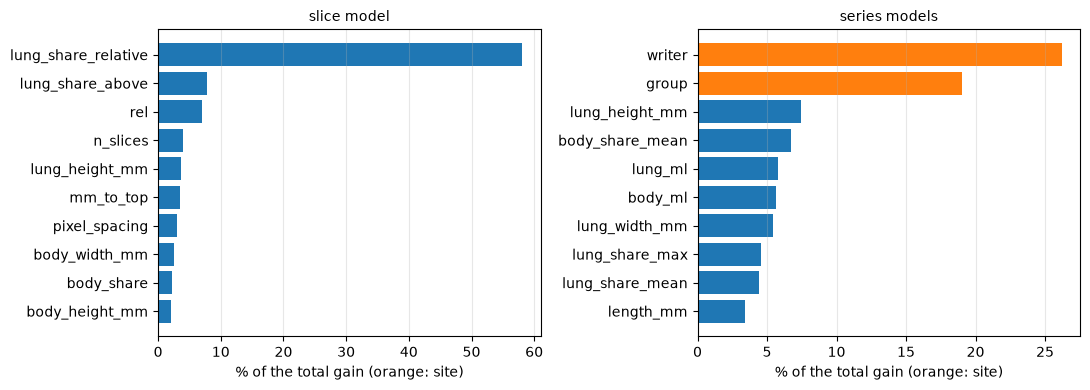

site share of the gain: slice model 1.5% | series models 45.2%
slice model: lung_share_relative 58.1% | box sizes 3.7% at most


9 s


,test-like,full,full: series labels,full: slices,the other two writers
"rate by place, 20 steps",0.3354,0.3432,0.1611,0.1821,0.3642
LightGBM without site,0.3209,0.3281,0.1593,0.1688,0.3477
LightGBM,0.3198,0.3192,0.1503,0.1688,0.3175


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, gain, title in [(axes[0], slice_gain, "slice model"), (axes[1], series_gain, "series models")]:
    top = gain.sort_values().tail(10)
    ax.barh(top.index, top * 100, color=["tab:orange" if c in SITE else "tab:blue" for c in top.index])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("% of the total gain (orange: site)")
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
print(f"site share of the gain: slice model {slice_gain[SITE].sum():.1%} | series models {series_gain[SITE].sum():.1%}")
print(f"slice model: lung_share_relative {slice_gain['lung_share_relative']:.1%} | box sizes {slice_gain[['body_height_mm', 'body_width_mm', 'lung_height_mm', 'lung_width_mm']].max():.1%} at most")

start = time.time()
*predictions["LightGBM without site"], _, _ = lightgbm_oof(slice_features.drop(columns=SITE), series_features.drop(columns=SITE))
print(f"{time.time() - start:.0f} s")
evaluate(["rate by place, 20 steps", "LightGBM without site", "LightGBM"])

**Decision**
- **No model gets the site as an input.** Without it, LightGBM loses 0.0089 on the full score but only 0.0011 on the test-like score, at the edge of the noise of section 6 (−0.0011 [−0.0022, +0.0000]).
- **From here on, decisions use the test-like score, and the full score is shown beside it.** An image model can recognise a site without being told, for example from its noise and kernel, and the test-like score rewards that less, since it leaves out the two writers that differ most.
- **The score to beat without images is a test-like score of 0.3209** (LightGBM without site; full score 0.3281).

### 4.1 Key findings

- **LightGBM improves the test-like score of the place by 0.0145:** 0.3354 to 0.3209. In the full score, almost all of the gain is in the slices (0.1821 to 0.1688).
- **`lung_share_relative` gives 58% of the gain of the slice model:** the lungs locate a slice better than its index. No box size gives more than 4% there.
- **The site gives 45% of the gain of the series models,** and the series labels gain little without it (0.1611 to 0.1593).
- **For these constant predictions, the test-like score is closer to the published public scores than the full score, but still above them:** plain rate 0.5754 (full 0.5988, public 0.56), q-weighted rate 0.4427 (0.4574, 0.44), 8 steps 0.3412 (0.3494, 0.33).

## 5. Reference points that use the labels

Predictions that use labels a model does not have, to put the scores in scale. They are not bounds.
- **series labels known:** the series labels are perfect, the slices stay at the rate by place. What is left is the slice part.
- **slice labels known:** the slices are perfect, the series labels stay at their rates. What is left is the series part.
- **neighbours' slice labels known:** each slice gets the rate of its labels below and above.

,test-like,full,full: series labels,full: slices,the other two writers
plain slice rate,0.5754,0.5988,0.1611,0.4377,0.6622
q-weighted slice rate,0.4427,0.4574,0.1611,0.2963,0.4973
"rate by place, 20 steps",0.3354,0.3432,0.1611,0.1821,0.3642
LightGBM without site,0.3209,0.3281,0.1593,0.1688,0.3477
LightGBM,0.3198,0.3192,0.1503,0.1688,0.3175
"series labels known, slices by place",0.1720,0.1821,0.0000,0.1821,0.2096
"slice labels known, series rates",0.1635,0.1611,0.1611,0.0000,0.1546
"neighbours' slice labels known, series rates",0.1753,0.1735,0.1611,0.0124,0.1685


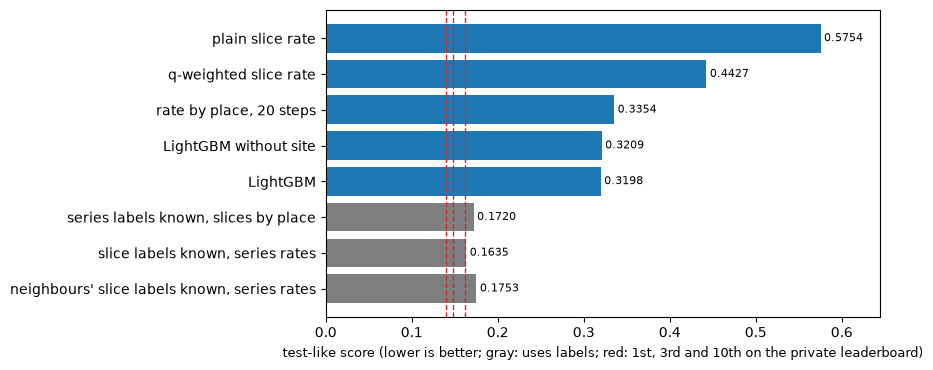

In [13]:
by_stack_label = train.assign(y=y_image).groupby(["series", "stack"])["y"]
train["below"], train["above"] = by_stack_label.shift(1).fillna(-1).astype(int), by_stack_label.shift(-1).fillna(-1).astype(int)
place = predictions["rate by place, 20 steps"]
predictions["series labels known, slices by place"] = (y_series, place[1])
predictions["slice labels known, series rates"] = (series_rates, y_image)
predictions["neighbours' slice labels known, series rates"] = (series_rates, oof_image_rates(["below", "above"]))
known = ["plain slice rate", "q-weighted slice rate", "rate by place, 20 steps", "LightGBM without site", "LightGBM", "series labels known, slices by place",
         "slice labels known, series rates", "neighbours' slice labels known, series rates"]
table = evaluate(known)
display(table)

values = table["test-like"].tolist()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(known[::-1], values[::-1], color=["tab:gray" if "known" in n else "tab:blue" for n in known[::-1]])
for i, v in enumerate(values[::-1]):
    ax.text(max(v, 0.162) + 0.004, i, f"{v:.4f}", va="center", fontsize=8)
for x in [0.140, 0.148, 0.162]:
    ax.axvline(x, color="tab:red", linewidth=1, linestyle="--")
ax.set_xlabel("test-like score (lower is better; gray: uses labels; red: 1st, 3rd and 10th on the private leaderboard)", fontsize=9)
ax.set_xlim(0, max(values) * 1.12)
plt.tight_layout()
plt.show()

### 5.1 Key findings

- **Both parts are large:** with perfect slices, constant series labels still have a test-like score of 0.1635, and with perfect series labels the rate by place has 0.1720. For scale, the 1st place scored about 0.18 on its own validation and 0.140 on the test set (00).
- **Neighbouring labels nearly settle the slices:** their part of the full score falls from 0.1821 to 0.0124. Labels change little from slice to slice, which a sequence model can use (05).

## 6. How precise is the validation?

The top of the leaderboard is tight: 3rd and 4th lie 0.004 apart, 1st and 3rd 0.008. Can the validation tell such differences apart? All on the test-like score.

First between folds:

In [14]:
losses = {}
for name, (p_series, p_image) in predictions.items():
    losses[name], series_weight = series_losses(y_series, p_series, image_series, y_image, p_image)

per_fold = pd.DataFrame({name: [losses[name][test_like & (series_fold == f)].sum() / series_weight[test_like & (series_fold == f)].sum() for f in range(N_FOLDS)]
                         for name in ["q-weighted slice rate", "rate by place, 20 steps", "LightGBM without site"]})
per_fold.index.name = "fold"
per_fold.loc["max - min"] = per_fold.max() - per_fold.min()
per_fold.round(4)

,q-weighted slice rate,"rate by place, 20 steps",LightGBM without site
fold,,,
0,0.4372,0.3389,0.3243
1,0.4509,0.3447,0.3212
2,0.4452,0.3324,0.3217
3,0.4411,0.3313,0.3219
4,0.4390,0.3298,0.3153
max - min,0.0137,0.0149,0.0090


The interval of a score comes from a bootstrap: the data are drawn again with replacement 2,000 times, the score is recomputed, and the middle 95% is the interval. Slices of a series are alike, so drawing single rows pretends there is more independent data than there is. Drawing whole series keeps them together:

In [15]:
p_series, p_image = predictions["LightGBM without site"]
counted = (weights > 0) & test_like[image_series]
row_losses = np.concatenate([(log_losses(y_series, p_series)[test_like] * SERIES_WEIGHTS).ravel(), (weights * log_losses(y_image, p_image))[counted]])
row_weights = np.concatenate([np.tile(SERIES_WEIGHTS, test_like.sum()), weights[counted]])
row_series = np.concatenate([np.repeat(np.flatnonzero(test_like), len(SERIES_WEIGHTS)), image_series[counted]])
start = time.time()
intervals = pd.DataFrame({"rows drawn": bootstrap(row_losses, row_weights), "series drawn": bootstrap(row_losses, row_weights, row_series)}).T
assert np.isclose(intervals.loc["series drawn", "mean"], losses["LightGBM without site"][test_like].sum() / series_weight[test_like].sum())
intervals["width"] = intervals["high"] - intervals["low"]
print(f"{len(row_losses):,} rows, {time.time() - start:.0f} s")
intervals.round(5)

409,885 rows, 42 s


,mean,low,high,width
rows drawn,0.32088,0.31742,0.32421,0.00680
series drawn,0.32088,0.31435,0.32717,0.01282


Two models are compared on the same series (paired): the bootstrap draws series and recomputes the difference. The steps of this notebook, and two LightGBM runs that differ only in their random seed:

In [16]:
start = time.time()
*predictions["LightGBM, another seed"], _, _ = lightgbm_oof(slice_features.drop(columns=SITE), series_features.drop(columns=SITE), seed=SEED + 1)
losses["LightGBM, another seed"], _ = series_losses(y_series, predictions["LightGBM, another seed"][0], image_series, y_image, predictions["LightGBM, another seed"][1])
print(f"{time.time() - start:.0f} s")
pairs = [("q-weighted slice rate", "rate by place, 20 steps"), ("rate by place, 8 steps", "rate by place, 20 steps"), ("rate by place, 20 steps", "LightGBM without site"),
         ("LightGBM without site", "LightGBM"), ("LightGBM without site", "LightGBM, another seed")]
paired = pd.DataFrame([{"from": a, "to": b, **paired_bootstrap(losses[a][test_like], losses[b][test_like], series_weight[test_like])} for a, b in pairs])
paired["width"] = paired["high"] - paired["low"]
paired.rename(columns={"mean": "difference"}).round(5)

9 s


,from,to,difference,low,high,width
0,q-weighted slice rate,"rate by place, 20 steps",-0.10725,-0.11438,-0.09997,0.01441
1,"rate by place, 8 steps","rate by place, 20 steps",-0.00575,-0.00638,-0.00511,0.00127
2,"rate by place, 20 steps",LightGBM without site,-0.01456,-0.01925,-0.01035,0.00889
3,LightGBM without site,LightGBM,-0.00109,-0.00218,0.00003,0.00221
4,LightGBM without site,"LightGBM, another seed",0.00034,-0.00024,0.00094,0.00118


### 6.1 Key findings

- **A single score moves a lot:** the folds differ by 0.009–0.015, and the 95% interval of the LightGBM score is 0.0128 wide, wider than the gap of 0.008 between the 1st and the 3rd place.
- **Drawing rows instead of series gives an interval 1.9 times too narrow** (0.0068 against 0.0128).
- **Paired differences are far more precise:** 8 to 20 steps is −0.0058 with an interval 0.0013 wide. Two LightGBM runs that differ only in the seed differ by +0.0003 [−0.0002, +0.0009].
- **So models are compared by the paired series bootstrap of their difference, and each pair is judged by its own interval.** A difference below about 0.001 counts as noise in any case: that is a floor, and a larger difference is not real just for being above it.

## Summary

- **Metric:** `pe.metrics` follows the published formula and passes its 15 unit tests. The slices carry 49.4% of the total weight.
- **Other stacks:** every slice outside the main stack gets 0.001. All 12,179 such slices in positive train series are negative, and the test files hold one. This adds 0.000003 on train.
- **Site:** 157 of the 158 series with several stacks and most of the site signal come from two writers with 2 of the 650 test series. No model gets the site as an input.
- **Two scores:** the test-like score, on the 5,647 series of the other three writers, makes the decisions; the full score, on all 7,279 series, is shown beside it.
- **Baselines without an image model:**

  | Prediction | Test-like score | Full score |
  |---|---|---|
  | plain slice rate | 0.5754 | 0.5988 |
  | q-weighted slice rate | 0.4427 | 0.4574 |
  | rate by place, 8 steps | 0.3412 | 0.3494 |
  | rate by place, 20 steps | 0.3354 | 0.3432 |
  | **LightGBM without site (the score to beat)** | **0.3209** | 0.3281 |
  | LightGBM with site | 0.3198 | 0.3192 |
  | reference: series labels known | 0.1720 | 0.1821 |
  | reference: slice labels known | 0.1635 | 0.1611 |
  | reference: neighbours' slice labels known | 0.1753 | 0.1735 |

- **Precision:** a single score has a 95% interval 0.0128 wide. Models are compared by the paired series bootstrap: each pair is judged by its own interval, and a difference below about 0.001 counts as noise in any case.

**Limits**
- Kaggle never published its metric code. The formula comes from the competition page and the clip at 1e-15 is our assumption.
- No score here is from the test set, and the test scores we compare with come from other people's predictions. Late submissions come in 06.
- 1,517 of the 2,167 test series are hidden, so the number of other-stack slices and the writers in them are unknown.
- Train series had one reader and test series three (00). The 1st place scored about 0.18 on its validation and 0.140 on the test set, so validation scores rank models but do not give their level on the test set.
- The noise floor of 0.001 comes from one pair of LightGBM seeds; we measure it again on the image models (04). The LightGBM settings were fixed once, not tuned.
- The intervals cover the choice of series, not retraining, the folds or repeated model selection.
- These scores did not go through the label consistency rule (06), and the baselines break it; later scores must be compared on the same footing.
- The two writers stay in training for now; whether they help a model on the other series is tested on the image models.